In [3]:
import pandas as pd
import matplotlib.pyplot as plt

# Load dataset
df = pd.read_csv(r"C:\Users\Madaan INFOTECH\Downloads\Student_Rating_Dataset_for_Practical.csv")



In [4]:
# Display first 5 rows
df.head()
print(df.columns)

Index(['Professor_ID', 'Minority', 'Gender', 'Tenure', 'Beauty', 'Evaluation',
       'Students', 'Age'],
      dtype='object')


In [5]:
pd.crosstab(df['Minority'], df['Tenure'])

Tenure,No,Yes
Minority,,
No,5,12
Yes,3,10


In [6]:
# Select visible minority professors
minority_professors = df[df['Minority'] == 'Yes']

# Select tenured visible minority professors
tenured_minority = minority_professors[
    minority_professors['Tenure'] == 'Yes'
]

# Calculate percentage
percentage = (
    len(tenured_minority) /
    len(minority_professors)
) * 100

print("Percentage of visible minorities who are tenured:",
      round(percentage, 2), "%")

Percentage of visible minorities who are tenured: 76.92 %


In [7]:
from scipy.stats import chi2_contingency

# Create contingency table
table = pd.crosstab(
    df['Minority'],
    df['Tenure']
)

# Chi-square test
chi2, p_value, dof, expected = chi2_contingency(
    table,
    correction=False
)

print("Chi-square =", round(chi2, 4))
print("p-value =", round(p_value, 4))

Chi-square = 0.1512
p-value = 0.6974


In [8]:
#2nd 
age_statistics = df.groupby('Tenure')['Age'].agg(
    ['mean', 'std']
)

print(age_statistics)

             mean       std
Tenure                     
No      54.875000  4.549333
Yes     45.045455  4.884156


In [9]:
difference = (
    df[df['Tenure'] == 'No']['Age'].mean()
    -
    df[df['Tenure'] == 'Yes']['Age'].mean()
)

print("Difference in mean age:",
      round(difference, 2), "years")

Difference in mean age: 9.83 years


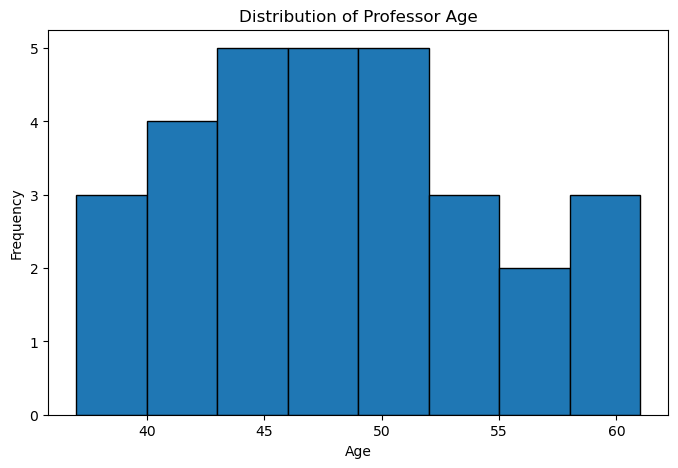

In [10]:
#3rd
plt.figure(figsize=(8, 5))

plt.hist(
    df['Age'],
    bins=8,
    edgecolor='black'
)

plt.xlabel("Age")
plt.ylabel("Frequency")
plt.title("Distribution of Professor Age")

plt.show()

#

<BarContainer object of 1 artists>

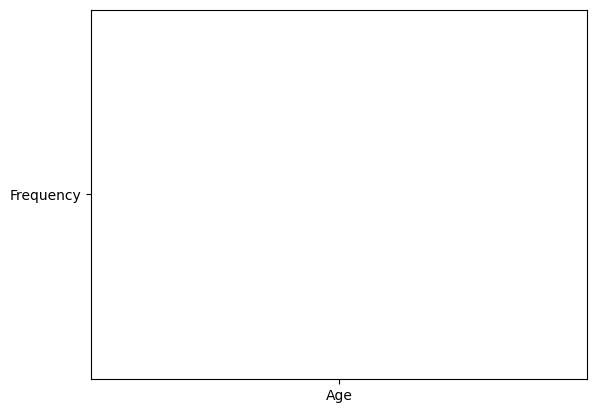

In [11]:
#4th
plt.bar('Age','Frequency')

<BarContainer object of 1 artists>

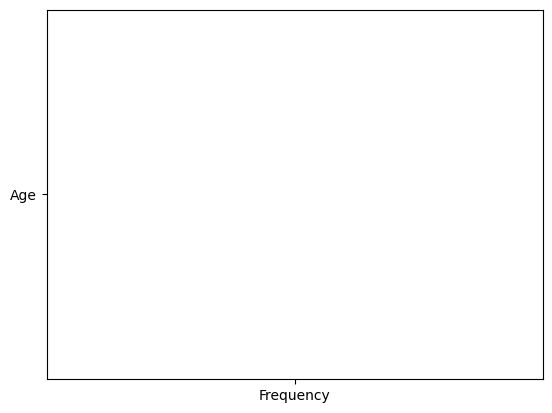

In [12]:
plt.barh("Age","Frequency")